#התקנות + imports

In [ ]:
import tensorflow as tf
print("TF:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices('GPU'))


TF: 2.19.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


#טעינת הדאטהסט (Oxford Flowers)

In [ ]:
!pip -q install tensorflow_datasets

import tensorflow as tf
import tensorflow_datasets as tfds
import matplotlib.pyplot as plt

AUTOTUNE = tf.data.AUTOTUNE
IMG_SIZE = 128
BATCH_SIZE = 16

#

# TensorFlow Datasets באמצעות (TFDS)Oxford Flowers 102 טעינת מאגר הנתונים

In [ ]:
ds_train = tfds.load("oxford_flowers102", split="train", as_supervised=True)
ds_val   = tfds.load("oxford_flowers102", split="validation", as_supervised=True)

print("loaded ✅")

Dl Completed...: 0 url [00:00, ? url/s]

Dl Size...: 0 MiB [00:00, ? MiB/s]

Extraction completed...: 0 file [00:00, ? file/s]

Generating splits...:   0%|          | 0/3 [00:00<?, ? splits/s]

Generating train examples...: 0 examples [00:00, ? examples/s]

...

Generating test examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_flowers102/incomplete.7EMJ0J_2.1.1/oxford_flowers102-test.tfrecord*…

Generating validation examples...: 0 examples [00:00, ? examples/s]

Shuffling /root/tensorflow_datasets/oxford_flowers102/incomplete.7EMJ0J_2.1.1/oxford_flowers102-validation.tfr…

Dataset oxford_flowers102 downloaded and prepared to /root/tensorflow_datasets/oxford_flowers102/2.1.1. Subsequent calls will reuse this data.
loaded ✅


#pipeline + תצוגת זוג

photo shape: (128, 128, 3) min/max: 0.0 1.0
sketch shape: (128, 128, 3) min/max: 0.0 1.0


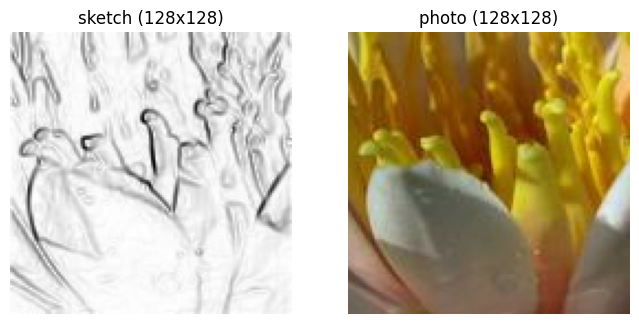

In [ ]:
# ===  (CLEAN, no resize): center-crop/pad to 128 + sketch + show ONE pair ===

import tensorflow as tf
import matplotlib.pyplot as plt

IMG_SIZE = 128

def to_128_crop_or_pad(img):
    # img: [H,W,3] uint8/float
    img = tf.cast(img, tf.float32)
    h = tf.shape(img)[0]
    w = tf.shape(img)[1]

    # center crop to at most 128x128
    crop_h = tf.minimum(h, IMG_SIZE)
    crop_w = tf.minimum(w, IMG_SIZE)
    offset_h = tf.maximum(0, (h - IMG_SIZE) // 2)
    offset_w = tf.maximum(0, (w - IMG_SIZE) // 2)

    img = tf.image.crop_to_bounding_box(img, offset_h, offset_w, crop_h, crop_w)

    # pad to exactly 128x128 if needed
    img = tf.image.pad_to_bounding_box(img, 0, 0, IMG_SIZE, IMG_SIZE)

    # back to 0..255 range (still float)
    img = tf.clip_by_value(img, 0.0, 255.0)
    return img  # [128,128,3] float

def photo_to_sketch(img_rgb_0_255):
    gray = tf.image.rgb_to_grayscale(img_rgb_0_255)  # [128,128,1]
    gray = gray / 255.0                              # 0..1

    gray4 = gray[tf.newaxis, ...]                    # [1,128,128,1]
    sobel = tf.image.sobel_edges(gray4)              # [1,128,128,1,2]

    gx = sobel[0, ..., 0]                            # [128,128,1]
    gy = sobel[0, ..., 1]
    mag = tf.sqrt(gx*gx + gy*gy)

    mag = mag / (tf.reduce_max(mag) + 1e-8)
    sketch = 1.0 - mag
    sketch = tf.tile(sketch, [1, 1, 3])              # [128,128,3]
    sketch = tf.clip_by_value(sketch, 0.0, 1.0)
    return sketch

def preprocess(image, label):
    image_128 = to_128_crop_or_pad(image)            # 0..255 float, 128x128
    photo = image_128 / 255.0                        # 0..1
    sketch = photo_to_sketch(image_128)              # 0..1
    return sketch, photo

# take ONE example and show it
img, label = next(iter(ds_train.take(1)))
sketch, photo = preprocess(img, label)

print("photo shape:", photo.shape, "min/max:", float(tf.reduce_min(photo)), float(tf.reduce_max(photo)))
print("sketch shape:", sketch.shape, "min/max:", float(tf.reduce_min(sketch)), float(tf.reduce_max(sketch)))

plt.figure(figsize=(8,4))
plt.subplot(1,2,1); plt.imshow(sketch.numpy()); plt.axis("off"); plt.title("sketch (128x128)")
plt.subplot(1,2,2); plt.imshow(photo.numpy());  plt.axis("off"); plt.title("photo (128x128)")
plt.show()

#בדיקת 4 זוגות
Show 4 pairs (uses the SAME preprocess you already have)

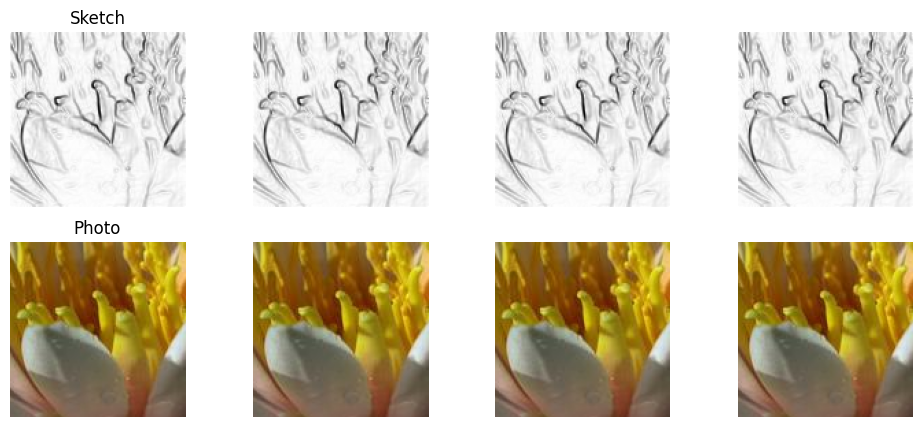

In [ ]:


import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))
for i in range(4):
    img, label = next(iter(ds_train.take(1)))
    sketch, photo = preprocess(img, label)

    plt.subplot(2, 4, i+1)
    plt.imshow(sketch.numpy())
    plt.axis("off")
    if i == 0: plt.title("Sketch")

    plt.subplot(2, 4, 4+i+1)
    plt.imshow(photo.numpy())
    plt.axis("off")
    if i == 0: plt.title("Photo")

plt.show()

# build batched training dataset (pairs) + show one batch

sketch batch shape: (16, 128, 128, 3)
photo  batch shape: (16, 128, 128, 3)


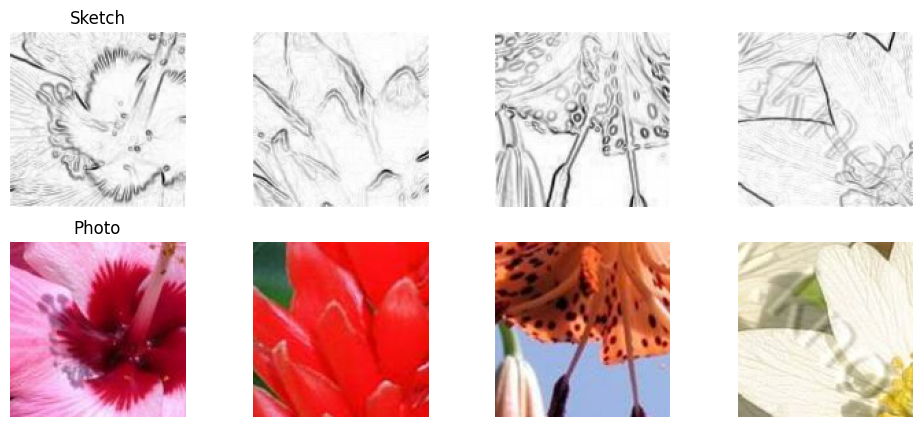

In [ ]:


import tensorflow as tf
import matplotlib.pyplot as plt

BATCH_SIZE = 16
AUTOTUNE = tf.data.AUTOTUNE

train_pairs = (
    ds_train
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .shuffle(1000)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

# take ONE batch
sketch_b, photo_b = next(iter(train_pairs))

print("sketch batch shape:", sketch_b.shape)  # should be (B,128,128,3)
print("photo  batch shape:", photo_b.shape)   # should be (B,128,128,3)

# show 4 from this batch
plt.figure(figsize=(12,5))
for i in range(4):
    plt.subplot(2,4,i+1);   plt.imshow(sketch_b[i].numpy()); plt.axis("off")
    if i == 0: plt.title("Sketch")
    plt.subplot(2,4,4+i+1); plt.imshow(photo_b[i].numpy());  plt.axis("off")
    if i == 0: plt.title("Photo")
plt.show()

#Baseline model (Method A) + sanity check

Model: "baseline_A"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 128, 128,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 128, 128,  │      1,792 │ input_layer_1[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 128, 128,  │     36,928 │ conv2d_11[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 64, 64,    │          0 │ conv2d_12[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_13 (Conv2D)  │ (None, 64, 64,    │     73,856 │ max_pooling2d_2[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_14 (Conv2D)  │ (None, 64, 64,    │    147,584 │ conv2d_13[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 32, 32,    │          0 │ conv2d_14[0][0]   │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_15 (Conv2D)  │ (None, 32, 32,    │    295,168 │ max_pooling2d_3[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_16 (Conv2D)  │ (None, 32, 32,    │    590,080 │ conv2d_15[0][0]   │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_2  │ (None, 64, 64,    │    295,040 │ conv2d_16[0][0]   │
│ (Conv2DTranspose)   │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_2       │ (None, 64, 64,    │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 256)              │            │ conv2d_14[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_17 (Conv2D)  │ (None, 64, 64,    │    295,040 │ concatenate_2[0]… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_18 (Conv2D)  │ (None, 64, 64,    │    147,584 │ conv2d_17[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose_3  │ (None, 128, 128,  │     73,792 │ conv2d_18[0][0]   │
│ (Conv2DTranspose)   │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate_3       │ (None, 128, 128,  │          0 │ conv2d_transpose… │
│ (Concatenate)       │ 128)              │            │ conv2d_12[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 128, 128,  │     73,792 │ concatenate_3[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 128, 128,  │     36,928 │ conv2d_19[0][0] 

 Total params: 2,067,779 (7.89 MB)

 Trainable params: 2,067,779 (7.89 MB)

 Non-trainable params: 0 (0.00 B)

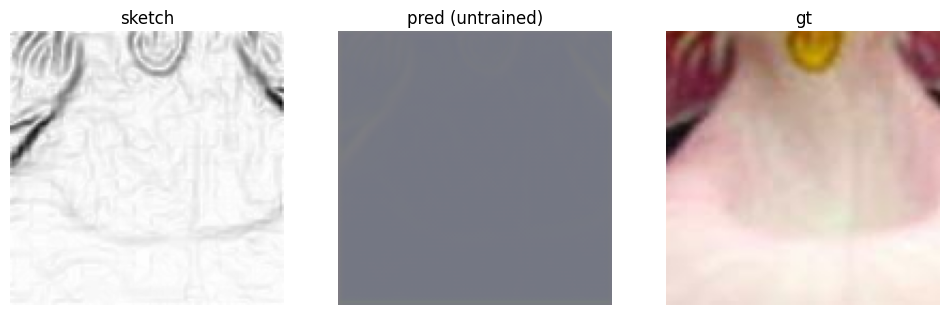

In [ ]:

import tensorflow as tf
import matplotlib.pyplot as plt

def make_baseline_model():
    inp = tf.keras.Input(shape=(128, 128, 3))  # sketch

    # Encoder
    x1 = tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu")(inp)
    x1 = tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu")(x1)
    p1 = tf.keras.layers.MaxPool2D()(x1)  # 64x64

    x2 = tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu")(p1)
    x2 = tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu")(x2)
    p2 = tf.keras.layers.MaxPool2D()(x2)  # 32x32

    x3 = tf.keras.layers.Conv2D(256, 3, padding="same", activation="relu")(p2)
    x3 = tf.keras.layers.Conv2D(256, 3, padding="same", activation="relu")(x3)

    # Decoder
    u2 = tf.keras.layers.Conv2DTranspose(128, 3, strides=2, padding="same", activation="relu")(x3)  # 64x64
    c2 = tf.keras.layers.Concatenate()([u2, x2])
    y2 = tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu")(c2)
    y2 = tf.keras.layers.Conv2D(128, 3, padding="same", activation="relu")(y2)

    u1 = tf.keras.layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu")(y2)   # 128x128
    c1 = tf.keras.layers.Concatenate()([u1, x1])
    y1 = tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu")(c1)
    y1 = tf.keras.layers.Conv2D(64, 3, padding="same", activation="relu")(y1)

    out = tf.keras.layers.Conv2D(3, 1, padding="same", activation="sigmoid")(y1)  # photo 0..1
    return tf.keras.Model(inp, out, name="baseline_A")

model_A = make_baseline_model()
model_A.summary()

# sanity check on one batch
sketch_b, photo_b = next(iter(train_pairs))
pred_b = model_A(sketch_b)

plt.figure(figsize=(12,4))
plt.subplot(1,3,1); plt.imshow(sketch_b[0].numpy()); plt.axis("off"); plt.title("sketch")
plt.subplot(1,3,2); plt.imshow(pred_b[0].numpy());   plt.axis("off"); plt.title("pred (untrained)")
plt.subplot(1,3,3); plt.imshow(photo_b[0].numpy());  plt.axis("off"); plt.title("gt")
plt.show()

**Compile**

In [ ]:
model_A.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="mae",   # אפשר גם mse
    metrics=["mae"]
)

**Valdation dataset**

In [ ]:
val_pairs = (
    ds_val
    .map(preprocess, num_parallel_calls=AUTOTUNE)
    .batch(BATCH_SIZE)
    .prefetch(AUTOTUNE)
)

**Train Model**

In [ ]:
EPOCHS = 10

history = model_A.fit(
    train_pairs,
    validation_data=val_pairs,
    epochs=EPOCHS
)

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 77s 714ms/step - loss: 0.2352 - mae: 0.2352 - val_loss: 0.2310 - val_mae: 0.2310
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 20s 236ms/step - loss: 0.2301 - mae: 0.2301 - val_loss: 0.2307 - val_mae: 0.2307
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 17s 207ms/step - loss: 0.2297 - mae: 0.2297 - val_loss: 0.2307 - val_mae: 0.2307
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 20s 230ms/step - loss: 0.2297 - mae: 0.2297 - val_loss: 0.2309 - val_mae: 0.2309
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 18s 213ms/step - loss: 0.2296 - mae: 0.2296 - val_loss: 0.2305 - val_mae: 0.2305
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 20s 231ms/step - loss: 0.2296 - mae: 0.2296 - val_loss: 0.2303 - val_mae: 0.2303
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 18s 221ms/step - loss: 0.2294 - mae: 0.2294 - val_loss: 0.2305 - val_mae: 0.2305
Epoch 8/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 20s 230ms/step - loss: 0.2294 - mae: 0.2294 - val_loss: 0.2302 - val_mae: 0.2302
Epoch 9/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 18s 215ms/

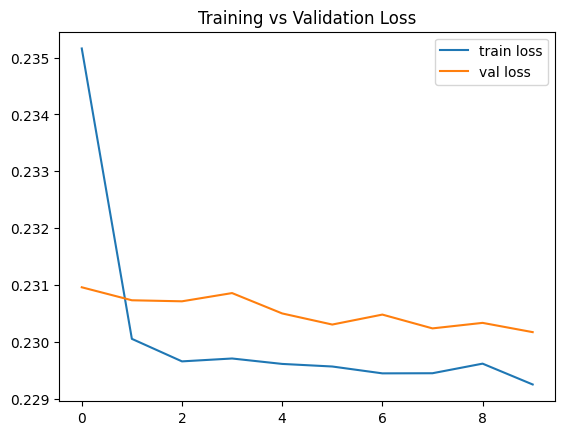

In [ ]:
plt.plot(history.history['loss'], label='train loss')
plt.plot(history.history['val_loss'], label='val loss')
plt.legend()
plt.title("Training vs Validation Loss")
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 626ms/step


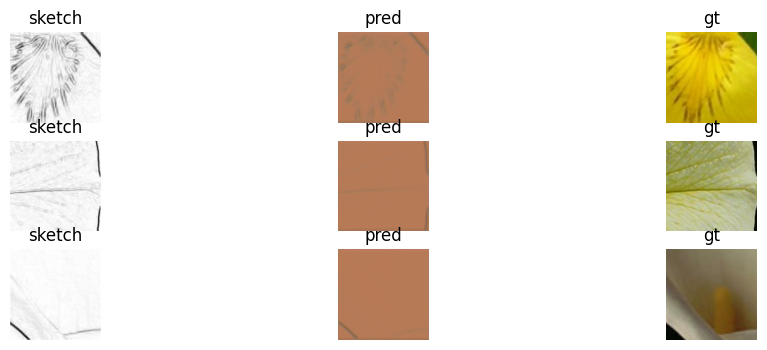

In [ ]:
sketch_b, photo_b = next(iter(train_pairs))
pred_b = model_A.predict(sketch_b)

plt.figure(figsize=(12,4))
for i in range(3):
    plt.subplot(3,3,i*3+1)
    plt.imshow(sketch_b[i])
    plt.title("sketch")
    plt.axis("off")

    plt.subplot(3,3,i*3+2)
    plt.imshow(pred_b[i])
    plt.title("pred")
    plt.axis("off")

    plt.subplot(3,3,i*3+3)
    plt.imshow(photo_b[i])
    plt.title("gt")
    plt.axis("off")

plt.show()

In [ ]:
model_A.save("baseline_model.keras")

In [ ]:
model_A.save_weights("baseline.weights.h5")

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

def run_experiment(loss_fn, lr, epochs=10):
    model = make_baseline_model()
    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=lr),
        loss=loss_fn,
        metrics=["mae"]
    )

    history = model.fit(
        train_pairs,
        validation_data=val_pairs,
        epochs=epochs,
        verbose=1
    )
    return model, history

In [ ]:
# Experiment 1: MAE + lr=1e-4
model_exp1, hist_exp1 = run_experiment(loss_fn="mae", lr=1e-4, epochs=10)

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 47s 416ms/step - loss: 0.2315 - mae: 0.2315 - val_loss: 0.2318 - val_mae: 0.2318
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 23s 233ms/step - loss: 0.2298 - mae: 0.2298 - val_loss: 0.2315 - val_mae: 0.2315
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 18s 213ms/step - loss: 0.2297 - mae: 0.2297 - val_loss: 0.2309 - val_mae: 0.2309
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 20s 227ms/step - loss: 0.2298 - mae: 0.2298 - val_loss: 0.2313 - val_mae: 0.2313
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 17s 209ms/step - loss: 0.2296 - mae: 0.2296 - val_loss: 0.2304 - val_mae: 0.2304
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 21s 256ms/step - loss: 0.2295 - mae: 0.2295 - val_loss: 0.2305 - val_mae: 0.2305
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 18s 223ms/step - loss: 0.2296 - mae: 0.2296 - val_loss: 0.2303 - val_mae: 0.2303
Epoch 8/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 20s 230ms/step - loss: 0.2293 - mae: 0.2293 - val_loss: 0.2303 - val_mae: 0.2303
Epoch 9/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 18s 217ms/

In [ ]:
# Experiment 2: MSE + lr=1e-4
model_exp2, hist_exp2 = run_experiment(loss_fn="mse", lr=1e-4, epochs=10)

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 29s 293ms/step - loss: 0.0751 - mae: 0.2327 - val_loss: 0.0755 - val_mae: 0.2324
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 18s 214ms/step - loss: 0.0746 - mae: 0.2316 - val_loss: 0.0757 - val_mae: 0.2316
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 20s 231ms/step - loss: 0.0746 - mae: 0.2313 - val_loss: 0.0754 - val_mae: 0.2325
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 18s 221ms/step - loss: 0.0747 - mae: 0.2317 - val_loss: 0.0756 - val_mae: 0.2321
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 20s 226ms/step - loss: 0.0745 - mae: 0.2314 - val_loss: 0.0758 - val_mae: 0.2315
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 18s 213ms/step - loss: 0.0744 - mae: 0.2311 - val_loss: 0.0757 - val_mae: 0.2342
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 20s 230ms/step - loss: 0.0745 - mae: 0.2312 - val_loss: 0.0757 - val_mae: 0.2320
Epoch 8/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 18s 212ms/step - loss: 0.0745 - mae: 0.2315 - val_loss: 0.0755 - val_mae: 0.2315
Epoch 9/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 19s 226ms/

In [ ]:
# Experiment 3: MAE + lr=1e-3
model_exp3, hist_exp3 = run_experiment(loss_fn="mae", lr=1e-3, epochs=10)

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 28s 285ms/step - loss: 0.2323 - mae: 0.2323 - val_loss: 0.2309 - val_mae: 0.2309
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 18s 217ms/step - loss: 0.2301 - mae: 0.2301 - val_loss: 0.2310 - val_mae: 0.2310
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 19s 223ms/step - loss: 0.2315 - mae: 0.2315 - val_loss: 0.2317 - val_mae: 0.2317
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 17s 204ms/step - loss: 0.2302 - mae: 0.2302 - val_loss: 0.2311 - val_mae: 0.2311
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 18s 214ms/step - loss: 0.2300 - mae: 0.2300 - val_loss: 0.2310 - val_mae: 0.2310
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 18s 214ms/step - loss: 0.2303 - mae: 0.2303 - val_loss: 0.2317 - val_mae: 0.2317
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 17s 204ms/step - loss: 0.2304 - mae: 0.2304 - val_loss: 0.2319 - val_mae: 0.2319
Epoch 8/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 19s 211ms/step - loss: 0.2297 - mae: 0.2297 - val_loss: 0.2339 - val_mae: 0.2339
Epoch 9/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 17s 203ms/

In [ ]:
# Experiment 3: MAE + lr=1e-3
model_exp3, hist_exp3 = run_experiment(loss_fn="mae", lr=1e-3, epochs=10)

Epoch 1/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 33s 288ms/step - loss: 0.2322 - mae: 0.2322 - val_loss: 0.2309 - val_mae: 0.2309
Epoch 2/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 18s 216ms/step - loss: 0.2312 - mae: 0.2312 - val_loss: 0.2316 - val_mae: 0.2316
Epoch 3/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 24s 297ms/step - loss: 0.2301 - mae: 0.2301 - val_loss: 0.2309 - val_mae: 0.2309
Epoch 4/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 24s 294ms/step - loss: 0.2303 - mae: 0.2303 - val_loss: 0.2306 - val_mae: 0.2306
Epoch 5/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 20s 251ms/step - loss: 0.2301 - mae: 0.2301 - val_loss: 0.2310 - val_mae: 0.2310
Epoch 6/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 17s 206ms/step - loss: 0.2300 - mae: 0.2300 - val_loss: 0.2325 - val_mae: 0.2325
Epoch 7/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 18s 212ms/step - loss: 0.2301 - mae: 0.2301 - val_loss: 0.2337 - val_mae: 0.2337
Epoch 8/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 18s 210ms/step - loss: 0.2299 - mae: 0.2299 - val_loss: 0.2306 - val_mae: 0.2306
Epoch 9/10
64/64 ━━━━━━━━━━━━━━━━━━━━ 17s 204ms/

In [ ]:
results = {
    "Exp1_MAE_1e-4": {
        "final_train_loss": hist_exp1.history["loss"][-1],
        "final_val_loss": hist_exp1.history["val_loss"][-1]
    },
    "Exp2_MSE_1e-4": {
        "final_train_loss": hist_exp2.history["loss"][-1],
        "final_val_loss": hist_exp2.history["val_loss"][-1]
    },
    "Exp3_MAE_1e-3": {
        "final_train_loss": hist_exp3.history["loss"][-1],
        "final_val_loss": hist_exp3.history["val_loss"][-1]
    }
}

for exp_name, vals in results.items():
    print(exp_name, "->", vals)

Exp1_MAE_1e-4 -> {'final_train_loss': 0.22951212525367737, 'final_val_loss': 0.23094120621681213}
Exp2_MSE_1e-4 -> {'final_train_loss': 0.0745379850268364, 'final_val_loss': 0.07539782673120499}
Exp3_MAE_1e-3 -> {'final_train_loss': 0.22951197624206543, 'final_val_loss': 0.23056140542030334}


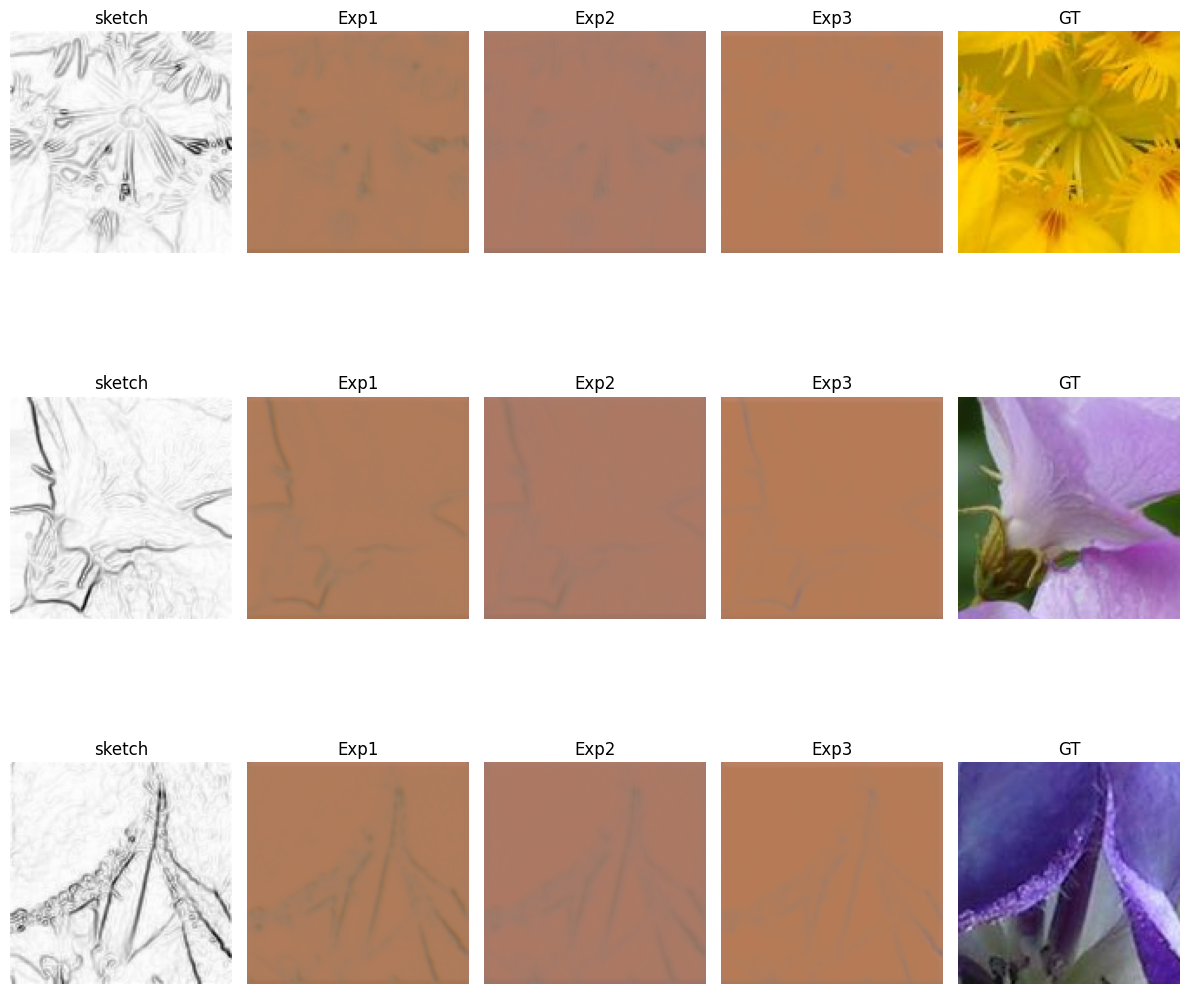

In [ ]:
sketch_b, photo_b = next(iter(val_pairs))

pred1 = model_exp1.predict(sketch_b[:3], verbose=0)
pred2 = model_exp2.predict(sketch_b[:3], verbose=0)
pred3 = model_exp3.predict(sketch_b[:3], verbose=0)

plt.figure(figsize=(12,12))

for i in range(3):
    plt.subplot(3,5,i*5+1)
    plt.imshow(sketch_b[i].numpy())
    plt.title("sketch")
    plt.axis("off")

    plt.subplot(3,5,i*5+2)
    plt.imshow(pred1[i])
    plt.title("Exp1")
    plt.axis("off")

    plt.subplot(3,5,i*5+3)
    plt.imshow(pred2[i])
    plt.title("Exp2")
    plt.axis("off")

    plt.subplot(3,5,i*5+4)
    plt.imshow(pred3[i])
    plt.title("Exp3")
    plt.axis("off")

    plt.subplot(3,5,i*5+5)
    plt.imshow(photo_b[i].numpy())
    plt.title("GT")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
final_val_losses = [
    hist_exp1.history["val_loss"][-1],
    hist_exp2.history["val_loss"][-1],
    hist_exp3.history["val_loss"][-1]
]

best_idx = int(np.argmin(final_val_losses))
print("Best experiment index:", best_idx)

if best_idx == 0:
    best_model = model_exp1
    best_name = "Exp1_MAE_1e-4"
elif best_idx == 1:
    best_model = model_exp2
    best_name = "Exp2_MSE_1e-4"
else:
    best_model = model_exp3
    best_name = "Exp3_MAE_1e-3"

print("Best model:", best_name)

Best experiment index: 1
Best model: Exp2_MSE_1e-4


In [ ]:
best_model.save("baseline_best_model.keras")
best_model.save_weights("baseline_best.weights.h5")
print("Saved best model successfully.")

Saved best model successfully.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import shutil

shutil.copy(
    "baseline_best_model.keras",
    "/content/drive/MyDrive/baseline_best_model.keras"
)

print("Model copied to Google Drive!")

Model copied to Google Drive!


In [ ]:
import matplotlib.pyplot as plt

sketch_b, photo_b = next(iter(val_pairs))

plt.imsave("example_sketch.png", sketch_b[0].numpy())

In [ ]:
from google.colab import files
files.download("example_sketch.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Experiment Comparison - Method A

We compared three baseline experiments:
1. MAE loss with learning rate 1e-4
2. MSE loss with learning rate 1e-4
3. MAE loss with learning rate 1e-3

Among the three baseline experiments, the best-performing model was **Exp2_MSE_1e-4**.
This model achieved the best validation performance and was therefore selected as the final baseline model for Method A.
The selected model was saved and will be used later in the test notebook.